Epidemics, Additional Exercises

By Pablo Angulo, Fabricio Macià and Daniel Sánchez-Mendoza for ETSIN@UPM

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integ
from scipy.interpolate import CubicSpline, lagrange
from scipy.optimize import bisect
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.interpolate import UnivariateSpline, CubicSpline

# Mathematical models in Epidemiology

We model the spread of smallpox in the country of Freedonia.

We consider that the study period is brief, and the dynamics of the disease predominate over natural dynamics (deaths, births, migrations...).

We limit ourselves to counting how many people are in one of the following states at each moment in time:

- **(S)usceptible.** People who have not had contact with the disease.
- **(I)nfected.** People who are contagious during an active episode.
- **(R)ecovered.** People who have developed \textit{immunity} to the disease.
- **(D)ead.** Deceased due to the disease.

The following system of equations describes the behavior of the population:
$$
\begin{align*}
\frac{d S}{dt}&= - \beta \frac{S I}{N},\\
\frac{d I}{dt}&= \beta \frac{S I}{N} -\gamma I-\eta I,\\
\frac{d R}{dt}&= \gamma I,\\
\frac{d D}{dt}&= \eta I,
\end{align*}
$$
where:
- $N=4\times 10^7$ is the initial population of Freedonia.
- $\beta$ models new infections: the potential contagion situations at an instant increase if the instantaneous rate of infections is proportional to the product $IS$.
- $\gamma I$ models successful recoveries.
- $\eta I$ models deaths.

In this exercise we are interested in the time period from $t_0=0$ to $t_f=365$.  We will assume the values $\beta=0.12$, $\eta=0.01$, $\gamma=0.04$.

Initially $D = 0$, $R = 0$, $I = 5000$.

The ratio $R_0=\frac{\beta}{\eta + \gamma}$ is the famous basic reproduction number. Keeping it below 1 is essential to control potential epidemic outbreaks.

### Section 1.1

- Write the iterations resulting from discretizing this system using the trapezoidal method and Heun's method.
- Indicate which of the previous iterations methods is implicit and which is explicit. Which methods is linear?

### Section 1.2

- Solve the previous system of equations using an adaptive numerical integration method and plot only the points generated by the adaptive method.
- Highlight the total number of people recovered at the end of the considered period.

In [14]:
N=4*(10**7)
beta=0.12
eta=0.01
gamma=0.04


def dzdt(t,x):
    S,I,R,D = x[0], x[1], x[2], x[3] #lo ponemos asi para que luego asocie cada derivada con cada valor del return
    return np.array([-beta*S*I/N , (beta*S*I/N)-(gamma*I)-(eta*I) , gamma*I , eta*I])


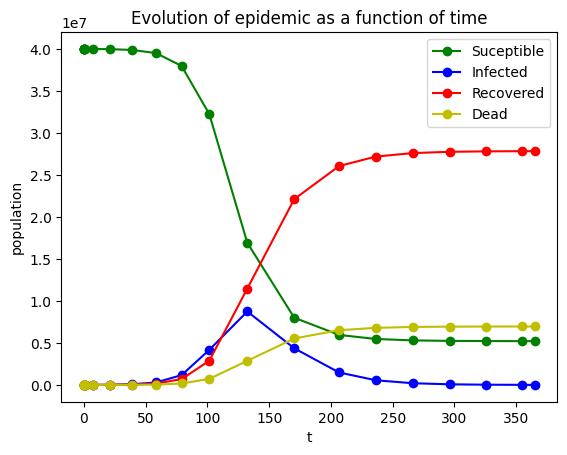

Number of recovered at the end of the period 27825365.39911635


In [15]:
x0=[N-5000,5000,0,0] #aqui co las condiciones iniciales igual, sabe que la primera variable se sustituye por ...
t0=0 
tf=365
t_span = [t0, tf]

sol = integ.solve_ivp(dzdt, t_span, x0, method="RK45")

ts = sol["t"]
Ss = sol["y"][0, :]
Is = sol["y"][1, :]
Rs = sol["y"][2, :]
Ds = sol["y"][3, :]

plt.plot(ts, Ss, "o-g", label="Suceptible")
plt.plot(ts, Is, "o-b", label="Infected")
plt.plot(ts, Rs, "o-r", label="Recovered")
plt.plot(ts, Ds, "o-y", label="Dead")
plt.title("Evolution of epidemic as a function of time")
plt.xlabel("t")
plt.ylabel("population")
plt.legend()
plt.show()

print("Number of recovered at the end of the period", sol["y"][2,-1])

### Section 2.1

Bound the error incurred when approximating the function $f(x)=\frac{\cos(2x)}{2}$ on $[-1,1]$ by its interpolating polynomial with 11 equally spaced nodes.

### Section 2.2

- Interpolate the points obtained by the adaptive method in Section 1.2 for the variable $D$ using either a cubic spline or the interpolating polynomial.
- Explain whether the chosen interpolation method is appropriate.

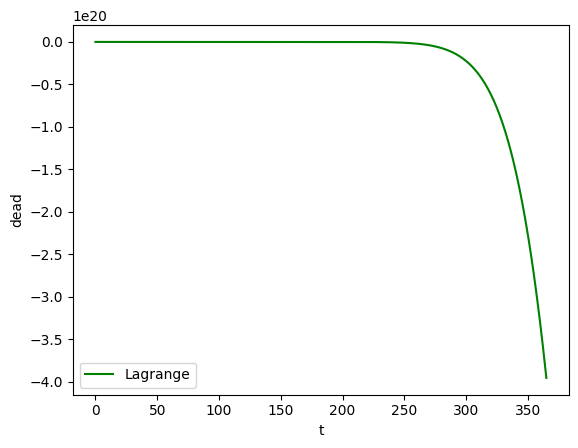

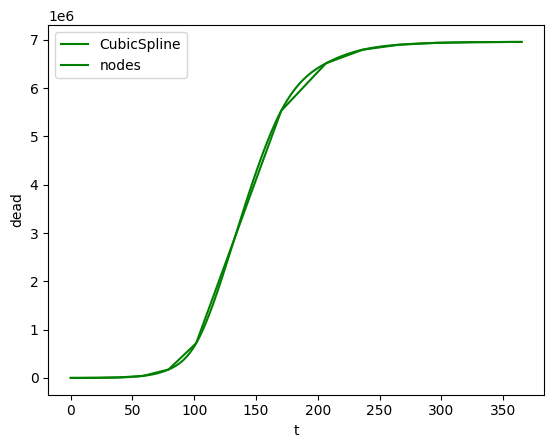

Text(0.5, 1.0, 'Evolution of epidemic as a function of time')

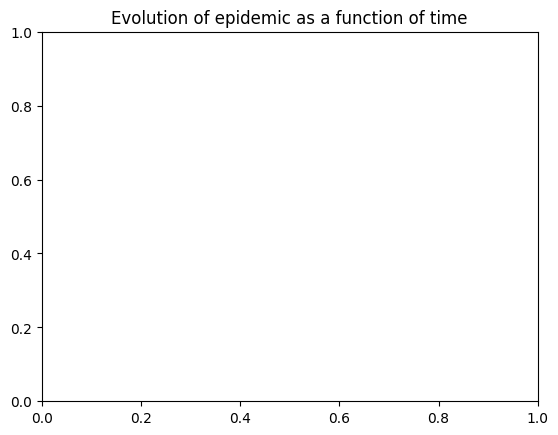

In [18]:
t_eval= np.linspace(t0, tf, (tf-t0)*3)

lag = lagrange(ts,Ds)
D_lag=lag(t_eval)
cs=CubicSpline(ts,Ds,bc_type="natural")
D_cs=cs(t_eval)

plt.plot(t_eval, D_lag, "g", label="Lagrange")
plt.xlabel("t")
plt.ylabel("dead")
plt.legend()
plt.show()
plt.plot(t_eval, D_cs, "g", label="CubicSpline")
plt.plot(ts, Ds, "g", label="nodes")
plt.xlabel("t")
plt.ylabel("dead")
plt.legend()
plt.show()


plt.title("Evolution of epidemic as a function of time")




### Section 3.1 

Compute the approximation and estimate the error made when approximating the integral
$$\int_{-1}^12^x dx$$
using the simple Simpson's rule.

### Section 3.2 

Approximate the total number of hospital admissions during the study period, assuming that $10\%$ of the infected require hospitalization. That is, approximate the integral:
$$\frac{1}{10}\int_{0}^{t_f} I(t)\;d t.$$

In [20]:
ts=np.linspace(t0,tf,(tf-t0)*2)
sol=integ.solve_ivp(dzdt,t_span,x0,method ="RK45",t_eval=ts)
result=integ.simpson(sol["y"][1,:],sol["t"])/10
print("total hospilatitiopn=",result)


total hospilatitiopn= 69563734.89406297


### Section 4

We assume that the values $\eta=0.01$, $\gamma =0.04$ are accurate (we have medical data), but there is much controversy over the value of $\beta$.

- Define a function $\beta\mapsto D(t_f)$ that maps $\beta$ to the total number of deaths at the end of the study period.
- Knowing that the total number of deaths at the end of the study period is $1.5\times 10^6$, find the value of $\beta$ that yields that amount using a numerical method of your choice.
- Discuss whether Newton's method is suitable for this purpose.


In [24]:
def death(beta):
    N=4*(10**7)
    eta=0.01
    gamma=0.04


    def dzdt(t,x):
        S,I,R,D = x[0], x[1], x[2], x[3] #lo ponemos asi para que luego asocie cada derivada con cada valor del return
        return np.array([-beta*S*I/N , (beta*S*I/N)-(gamma*I)-(eta*I) , gamma*I , eta*I])

        return Ds[-1]
    
    x0=[N-5000,5000,0,0] #aqui co las condiciones iniciales igual, sabe que la primera variable se sustituye por ...
    t0=0 
    tf=365
    t_span = [t0, tf]

    sol = integ.solve_ivp(dzdt, t_span, x0, method="RK45")
    Ds = sol["y"][3, :]
    
    return Ds[-1]


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


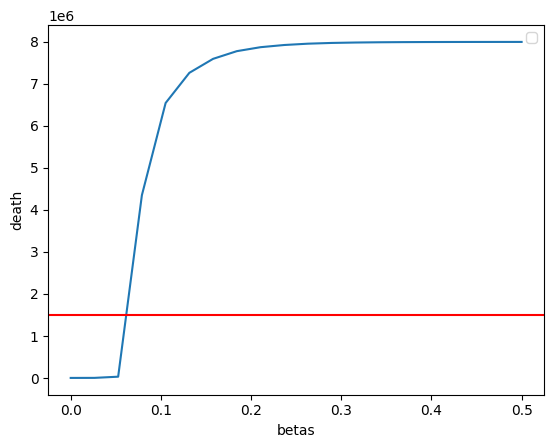

In [41]:
betas = np.linspace(0, 0.5,20)
Des = np.zeros_like(betas)
for j in range(len(betas)):
    Des[j] = death(betas[j])
    
plt.plot(betas, Des)
plt.axhline(y=1.5e6,color='r')
plt.xlabel("betas")
plt.ylabel("death")
plt.legend()
plt.show()

In [40]:
def f(beta):
    return death(beta)-1.5e6
r1=bisect(f,0,0.1)
print("beta=",r1)

beta= 0.06898177029943328


### Section 5

Add to the system of equations a 'loss of immunity' term $\mu R$, which models the transition of people from Recovered back to Susceptible:
$$
\begin{align*}
\frac{d S}{dt}&= - \beta \frac{S I}{N}+\mu R,\\
\frac{d I}{dt}&= \beta \frac{S I}{N} -\gamma I-\eta I,\\
\frac{d R}{dt}&= \gamma I-\mu R,\\
\frac{d D}{dt}&= \eta I.
\end{align*}
$$

Choose two sets of parameters $(\beta,\eta,\gamma,\mu)$, one with $R_0>1$ and the other with $R_0<1$. Plot the solution of the two corresponding systems up to $t_f=2\times 365$. What do you observe?

In [46]:
#elijo los valores para q r0>1 (𝑅0=𝛽/𝜂+𝛾)
N=4*(10**7)
beta=0.12
eta=0.01
gamma=0.04


def dzdt(t,x,mu=0.3):
    S,I,R,D = x[0], x[1], x[2], x[3] #lo ponemos asi para que luego asocie cada derivada con cada valor del return
    return np.array([-beta*S*I/N +mu*R , (beta*S*I/N)-(gamma*I)-(eta*I) , gamma*I -mu*R , eta*I])


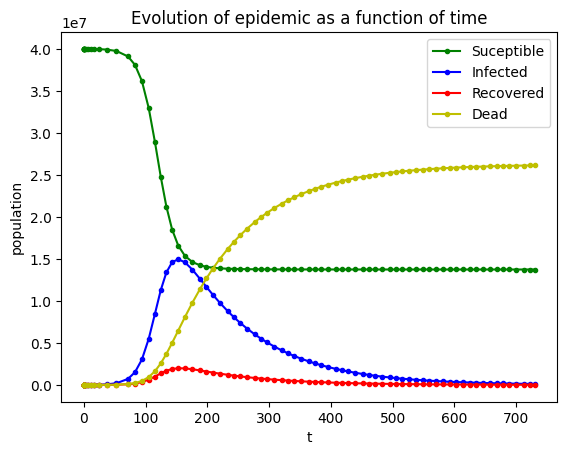

Number of recovered at the end of the period 15510.002036512169


In [48]:
x0=[N-5000,5000,0,0] #aqui co las condiciones iniciales igual, sabe que la primera variable se sustituye por ...
t0=0 
tf=365*2
t_span = [t0, tf]

sol = integ.solve_ivp(dzdt, t_span, x0, method="RK45")

ts = sol["t"]
Ss = sol["y"][0, :]
Is = sol["y"][1, :]
Rs = sol["y"][2, :]
Ds = sol["y"][3, :]

plt.plot(ts, Ss, ".-g", label="Suceptible")
plt.plot(ts, Is, ".-b", label="Infected")
plt.plot(ts, Rs, ".-r", label="Recovered")
plt.plot(ts, Ds, ".-y", label="Dead")
plt.title("Evolution of epidemic as a function of time")
plt.xlabel("t")
plt.ylabel("population")
plt.legend()
plt.show()

print("Number of recovered at the end of the period", sol["y"][2,-1])